# Simple RNN for IMDb Sentiment

Classify movie-review sentiment and study sequence length, hidden-state size, and recurrent gradient behavior.

Completed as part of my Deep Learning coursework. The notebook combines implementation, experiments, results, and the concepts explored.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

PALETTE = ['#2563eb', '#0891b2', '#ea580c', '#7c3aed', '#16a34a']
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titleweight': 'bold',
                     'axes.labelsize': 10, 'font.size': 10})

def show_architecture(stages, title):
    """Draw a compact network/data-flow diagram with readable layer dimensions."""
    columns = min(4, len(stages))
    rows = (len(stages) + columns - 1) // columns
    fig, ax = plt.subplots(figsize=(12, 2.1 * rows))
    ax.set_xlim(-.2, columns * 3); ax.set_ylim(-.2, rows * 2)
    ax.axis('off')
    centers=[]
    for i, label in enumerate(stages):
        row,col=divmod(i,columns)
        if row % 2: col=columns-1-col
        x=col*3; y=(rows-1-row)*2+.3
        box=FancyBboxPatch((x,y),2.4,1.25,boxstyle='round,pad=0.12',
                           facecolor=PALETTE[i%len(PALETTE)],edgecolor='none',alpha=.94)
        ax.add_patch(box)
        ax.text(x+1.2,y+.625,label,ha='center',va='center',color='white',fontsize=10)
        centers.append((x+1.2,y+.625))
    for (x1,y1),(x2,y2) in zip(centers,centers[1:]):
        if y1==y2:
            direction=1 if x2>x1 else -1
            start=(x1+direction*1.35,y1); end=(x2-direction*1.35,y2)
        else: start=(x1,y1-.75); end=(x2,y2+.75)
        ax.annotate('',xy=end,xytext=start,arrowprops={'arrowstyle':'->','color':'#475569','lw':1.8})
    ax.set_title(title,pad=12)
    plt.tight_layout(); plt.show()

## Model overview

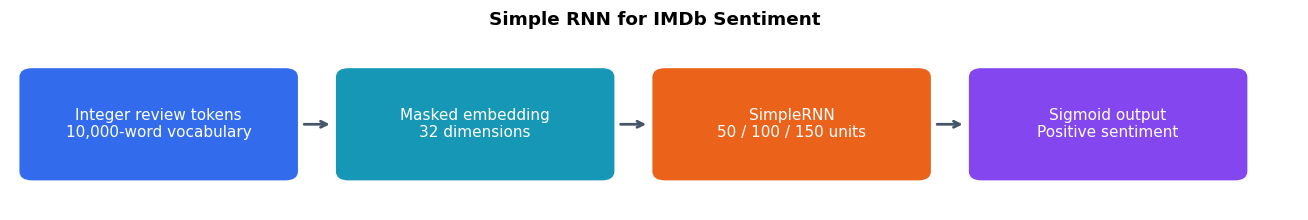

In [2]:
show_architecture(['Integer review tokens\n10,000-word vocabulary', 'Masked embedding\n32 dimensions', 'SimpleRNN\n50 / 100 / 150 units', 'Sigmoid output\nPositive sentiment'], 'Simple RNN for IMDb Sentiment')

## Learning Goals

- Understand sentiment classification as a sequence-learning problem.
- Convert text into numerical sequences.
- Understand padding and fixed sequence length.
- Understand the embedding layer and hidden state of an RNN.
- Implement a Simple RNN using Keras.
- Understand unrolling and Backpropagation Through Time (BPTT).
- Understand vanishing and exploding gradients.
- Analyze maximum review length and number of hidden units.

### Conceptual explanation

**A movie review is represented as a sequence of words. Why is the order of words important for sentiment classification? Give one example where changing the order of words changes the meaning or sentiment of a sentence.**

### Answer

The order of words is important because the meaning and sentiment of a sentence depend on how words are arranged and how earlier words provide context for later words. For example, **“Not good, but entertaining”** emphasizes an entertaining experience, while **“Entertaining, but not good”** emphasizes a negative judgment. These sentences use the same words in different orders; the clause after “but” changes the emphasis.

In [3]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import imdb
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, SimpleRNN, Embedding
from tensorflow.keras.preprocessing.sequence import pad_sequences

np.random.seed(1)
tf.random.set_seed(1)

print("TensorFlow version:", tf.__version__)


from IPython.display import display

def reset_experiment():
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(1)

TensorFlow version: 2.20.0


In [4]:
# Default settings
vocabulary_size = 10000
max_review_length = 500
embedding_dim = 32

print("Vocabulary size:", vocabulary_size)
print("Maximum review length:", max_review_length)
print("Embedding dimension:", embedding_dim)


Vocabulary size: 10000
Maximum review length: 500
Embedding dimension: 32


### Conceptual explanation

**Why do we limit the vocabulary to 10,000 words instead of using every possible word in the dataset?**

### Answer

Limiting the vocabulary controls the size of the embedding matrix and keeps the model computationally manageable. Very rare words contribute little useful information and would increase memory usage and the number of parameters. Words outside the selected vocabulary can be represented using the dataset's unknown-word handling.

### Conceptual explanation

**What is the purpose of limiting the maximum review length to 500?**

### Answer

A maximum length gives every review a fixed sequence size, making batch processing possible and bounding the computational cost of the RNN. Reviews shorter than the limit are padded, while reviews longer than the limit are truncated. The trade-off is that truncation can remove information from long reviews.

## Tokenization

The IMDb dataset is already represented as sequences of integer word indices. Neural networks operate on these numerical representations rather than raw English words.

### Conceptual explanation

**1. What does each integer represent?**  
Each integer is an index/token corresponding to a word in the IMDb vocabulary.

**2. Does the numerical value of a word's token indicate that the word is more important than a word with a smaller token value? Explain.**  
No. A token number is an identifier, not a sentiment score or importance score. Its numerical magnitude does not mean that the word is more important. The embedding layer learns a vector representation for each token.

## Load data

In [5]:
# Populate the Keras cache from the attached, original IMDb data files.
from pathlib import Path
import shutil, hashlib
cache = Path.home() / '.keras/datasets'
cache.mkdir(parents=True, exist_ok=True)
for filename in ['imdb.npz', 'imdb_word_index.json']:
    matches = list(Path('/kaggle/input').rglob(filename))
    if not matches:
        raise FileNotFoundError(f'Missing attached IMDb resource: {filename}')
    shutil.copy2(matches[0], cache / filename)
# Load the raw IMDb sequences once so every experiment starts from the same data.
(X_train_raw, y_train), (X_test_raw, y_test) = imdb.load_data(num_words=vocabulary_size)

print("Number of training reviews:", len(X_train_raw))
print("Number of testing reviews:", len(X_test_raw))
print("Length of first and fifth review before padding:",
      len(X_train_raw[0]), len(X_train_raw[4]))
print("First review:", X_train_raw[0])
print("First label:", y_train[0])


Number of training reviews: 25000
Number of testing reviews: 25000
Length of first and fifth review before padding: 218 147
First review: [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50, 670, 2, 9, 35, 480, 284, 5, 150, 4, 172, 112, 167, 2, 336, 385, 39, 4, 172, 4536, 1111, 17, 546, 38, 13, 447, 4, 192, 50, 16, 6, 147, 2025, 19, 14, 22, 4, 1920, 4613, 469, 4, 22, 71, 87, 12, 16, 43, 530, 38, 76, 15, 13, 1247, 4, 22, 17, 515, 17, 12, 16, 626, 18, 2, 5, 62, 386, 12, 8, 316, 8, 106, 5, 4, 2223, 5244, 16, 480, 66, 3785, 33, 4, 130, 12, 16, 38, 619, 5, 25, 124, 51, 36, 135, 48, 25, 1415, 33, 6, 22, 12, 215, 28, 77, 52, 5, 14, 407, 16, 82, 2, 8, 4, 107, 117, 5952, 15, 256, 4, 2, 7, 3766, 5, 723, 36, 71, 43, 530, 476, 26, 400, 317, 46, 7, 4, 2, 1029, 13, 104, 88, 4, 381, 15, 297, 98, 32, 2071, 56, 26, 141, 6, 194, 7486, 18, 4, 226, 22, 21, 134, 476, 26, 480, 5, 144, 30, 5535, 18, 51, 36, 28, 224, 92, 25, 104, 4, 226, 65, 16, 38,

### Review-length distribution

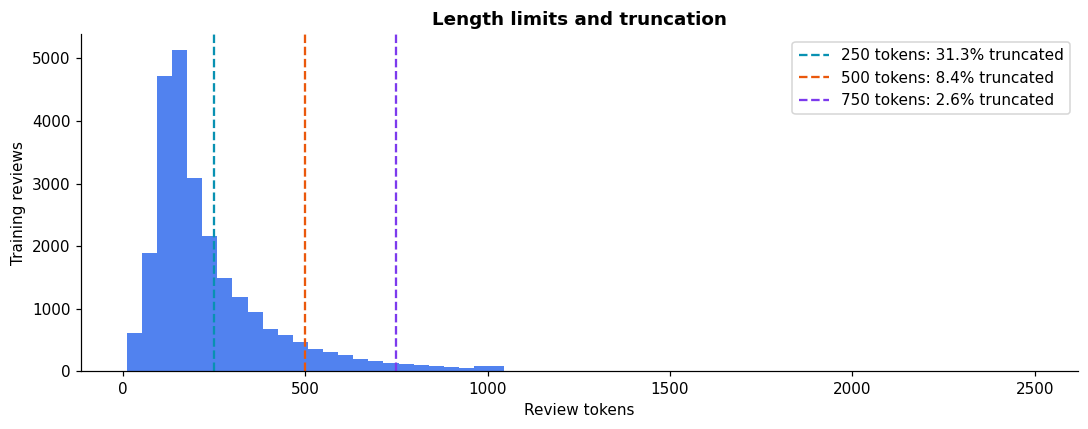

In [6]:
lengths=np.asarray([len(review) for review in X_train_raw])
fig,ax=plt.subplots(figsize=(10,4)); ax.hist(lengths,bins=60,color=PALETTE[0],alpha=.8)
for color,limit in zip(PALETTE[1:4],[250,500,750]):
    ax.axvline(limit,color=color,linestyle='--',label=f'{limit} tokens: {(lengths>limit).mean():.1%} truncated')
ax.set(xlabel='Review tokens',ylabel='Training reviews',title='Length limits and truncation'); ax.legend()
plt.tight_layout(); plt.show()

### Conceptual explanation

**Examine the lengths of the first and fifth reviews before padding. Why do the two reviews have different sequence lengths? Why is this a problem when training neural networks using batches of data?**

### Answer

Different reviews naturally contain different numbers of words, so their token sequences have different lengths. A neural network processes a batch as a tensor with consistent dimensions, so variable-length sequences cannot be directly stacked into a normal dense batch tensor. Padding or another sequence-handling mechanism is therefore required to make the dimensions compatible.

## Preprocess data

`pad_sequences` makes all reviews have the selected maximum length. With the default Keras behavior, shorter sequences are padded and longer sequences are truncated.


This notebook explicitly pads at the beginning and retains the final tokens when truncating. `Embedding(mask_zero=True)` tells the RNN to ignore padding tokens, rather than treating zero as a review word.

In [7]:
X_train = pad_sequences(X_train_raw, maxlen=max_review_length, padding="pre", truncating="pre")
X_test = pad_sequences(X_test_raw, maxlen=max_review_length, padding="pre", truncating="pre")

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("Length of first and fifth review after padding:",
      len(X_train[0]), len(X_train[4]))


X_train shape: (25000, 500)
X_test shape: (25000, 500)
Length of first and fifth review after padding: 500 500


### Padding and truncation illustration

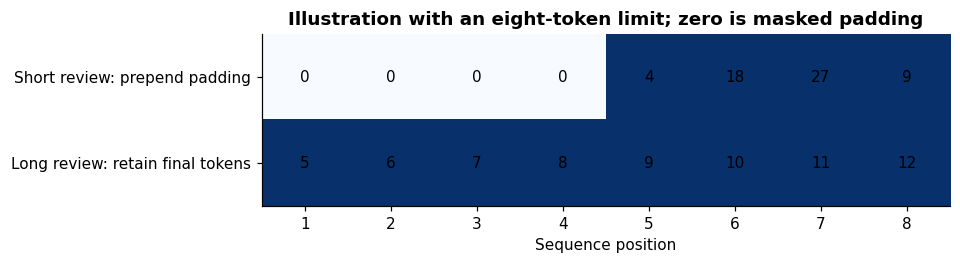

In [8]:
short=np.array([4,18,27,9]); long=np.arange(1,13)
illustration=np.stack([pad_sequences([short],maxlen=8,padding='pre',truncating='pre')[0],
                       pad_sequences([long],maxlen=8,padding='pre',truncating='pre')[0]])
fig,ax=plt.subplots(figsize=(10,2.5)); ax.imshow(illustration!=0,cmap='Blues',vmin=0,vmax=1)
for row in range(2):
    for col in range(8):ax.text(col,row,str(illustration[row,col]),ha='center',va='center')
ax.set_yticks([0,1],['Short review: prepend padding','Long review: retain final tokens']); ax.set_xticks(range(8),range(1,9))
ax.set(xlabel='Sequence position',title='Illustration with an eight-token limit; zero is masked padding')
plt.tight_layout(); plt.show()

### Conceptual explanation

**1. What happens to a review shorter than 500 words?**  
It is padded with zeros until it reaches length 500.

**2. What happens to a review longer than 500 words?**  
It is truncated to the selected maximum length, so some tokens are discarded.

**3. Why is it necessary for all reviews in a batch to have the same length?**  
A batch is represented as a rectangular tensor. Equal sequence lengths allow all reviews to be stacked into one tensor and processed efficiently in parallel.

## Simple RNN architecture

A SimpleRNN updates its hidden state at each time step:

$$h_t=\tanh(W_xx_t+W_hh_{t-1}+b).$$

Here $x_t$ is the token embedding. Keras SimpleRNN uses tanh by default. The recurrent weights are shared across time; the final hidden state is passed to a sigmoid classifier. Padding is masked by the embedding layer.

### Conceptual explanation

Consider:

`x₁ → x₂ → x₃ → x₄`  
`h₁ → h₂ → h₃ → h₄`

### Answer

1. **What information is used to calculate `h₂`?**  
   `h₂` uses the current input `x₂` and the previous hidden state `h₁`.

2. **What information is used to calculate `h₄`?**  
   `h₄` uses `x₄` and `h₃`. Since `h₃` contains information propagated from earlier states, `h₄` can indirectly contain information from earlier inputs.

3. **How can information from `x₁` influence `h₄`?**  
   `x₁` influences `h₁`, which influences `h₂`, then `h₃`, and finally `h₄`.

4. **What is the role of `hₜ₋₁` in the RNN?**  
   It carries information from previous time steps and provides context for computing the current hidden state.

### Conceptual explanation

```text
h0 ----> h1 ----> h2 ----> h3 ----> h4 ----> sigmoid ----> sentiment
          ^       ^       ^       ^
          |       |       |       |
        "The"  "movie"   "was"  "excellent"
```

Each hidden state receives the current token embedding and the preceding hidden state. The same input-to-hidden and hidden-to-hidden matrices are reused at every step. The diagram shows four recurrent steps; training propagates gradients backward along these connections.

In [9]:
def build_rnn(maxlen, hidden_units=100, vocab_size=10000, emb_dim=32):
    model = Sequential([
        Embedding(vocab_size, emb_dim, mask_zero=True),
        SimpleRNN(hidden_units),
        Dense(1, activation="sigmoid")
    ])
    model.build((None, maxlen))
    model.compile(
        loss="binary_crossentropy",
        optimizer="adam",
        metrics=["accuracy"]
    )
    return model


def run_length_experiment(maxlen, epochs=3, batch_size=64):
    Xtr = pad_sequences(X_train_raw, maxlen=maxlen, padding="pre", truncating="pre")
    Xte = pad_sequences(X_test_raw, maxlen=maxlen, padding="pre", truncating="pre")

    # Reset seeds so the comparison is reproducible as far as the runtime permits.
    reset_experiment()

    model = build_rnn(maxlen=maxlen, hidden_units=100)

    history = model.fit(
        Xtr, y_train,
        epochs=epochs,
        batch_size=batch_size,
        validation_split=0.1,
        verbose=1
    )

    loss, accuracy = model.evaluate(Xte, y_test, verbose=0)

    return {
        "max_review_length": maxlen,
        "X_train_shape": Xtr.shape,
        "X_test_shape": Xte.shape,
        "test_accuracy": accuracy,
        "history": history,
        "model": model
    }

In [10]:
# Baseline/default model: max_review_length = 500 and SimpleRNN(100)
max_review_length = 500
X_train_500 = pad_sequences(X_train_raw, maxlen=max_review_length, padding="pre", truncating="pre")
X_test_500 = pad_sequences(X_test_raw, maxlen=max_review_length, padding="pre", truncating="pre")

baseline_model = build_rnn(maxlen=500, hidden_units=100)

print("Baseline model summary:")
baseline_model.summary()


I0000 00:00:1791622428.516032      17 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791622428.519291      17 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Baseline model summary:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 500, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 100)            │        13,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           101 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 333,401 (1.27 MB)

 Trainable params: 333,401 (1.27 MB)

 Non-trainable params: 0 (0.00 B)

### Conceptual explanation

### Answer

1. **What is the role of the Embedding layer?**  
   It converts integer word IDs into dense numerical vectors. Instead of treating token IDs as meaningful numerical magnitudes, the model learns a vector representation for each vocabulary item.

2. **What is the role of the SimpleRNN layer?**  
   It processes the sequence one time step at a time, updates the hidden state, and captures information from the sequence for the final classification.

3. **What does the value 100 in `SimpleRNN(100)` represent?**  
   It represents 100 hidden units in the RNN. The hidden state at each time step therefore has 100 components.

4. **Why is the final layer using one neuron with a sigmoid activation?**  
   This is a binary classification problem. A single sigmoid output produces a value between 0 and 1 that can be interpreted as the predicted probability of the positive class.

In [11]:
# Execute the baseline model explicitly, as required before modifications.
reset_experiment()

baseline_model = build_rnn(maxlen=500, hidden_units=100)
baseline_history = baseline_model.fit(
    X_train_500, y_train,
    epochs=3,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

baseline_loss, baseline_accuracy = baseline_model.evaluate(
    X_test_500, y_test, verbose=0
)

print(f"Baseline test accuracy: {baseline_accuracy * 100:.2f}%")


Epoch 1/3


  1/352 ━━━━━━━━━━━━━━━━━━━━ 17:31 3s/step - accuracy: 0.5469 - loss: 0.6819

  3/352 ━━━━━━━━━━━━━━━━━━━━ 16s 48ms/step - accuracy: 0.5226 - loss: 0.6880

I0000 00:00:1791622433.543385      53 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


  5/352 ━━━━━━━━━━━━━━━━━━━━ 15s 45ms/step - accuracy: 0.5139 - loss: 0.6950

...

347/352 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.8021 - loss: 0.4391

349/352 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.8020 - loss: 0.4392

351/352 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.8020 - loss: 0.4393

352/352 ━━━━━━━━━━━━━━━━━━━━ 13s 38ms/step - accuracy: 0.7892 - loss: 0.4512 - val_accuracy: 0.7760 - val_loss: 0.4742


Baseline test accuracy: 78.47%


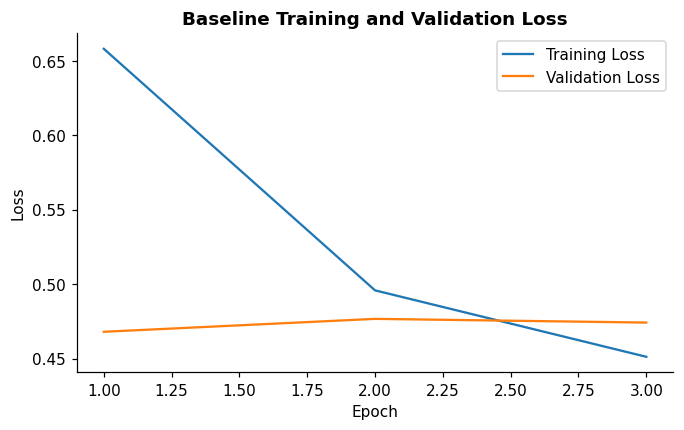

In [12]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(baseline_history.history["loss"]) + 1), baseline_history.history["loss"], label="Training Loss")
plt.plot(range(1, len(baseline_history.history["val_loss"]) + 1), baseline_history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Baseline Training and Validation Loss")
plt.legend()
plt.show()


### Conceptual explanation

**Examine the training and validation loss curves.**

### Answer

1. **Does the loss decrease as training progresses?**  
   This should be determined from the executed plot. If the training-loss curve decreases across epochs, the model is learning from the training data.

2. **Is there any indication that the model is beginning to overfit?**  
   Overfitting is suggested when training loss continues to decrease while validation loss stops decreasing or begins increasing. The actual conclusion should be based on the retained baseline plot.

3. **What additional information does validation loss provide compared with training loss alone?**  
   Validation loss indicates how well the model generalizes to data that was not used for parameter updates. It therefore helps identify overfitting that may not be visible from training loss alone.

## Sequence-length study – Modify Maximum Review Length

The required values are **250, 500, and 750**.

For each value, the notebook below:
1. Pads the original raw sequences from scratch.
2. Builds a new Simple RNN.
3. Trains the model for 3 epochs.
4. Evaluates it on the test set.
5. Records training shape, testing shape, and test accuracy.

This avoids accidentally padding an already-padded dataset.

In [13]:
length_results = []

for length in [250, 500, 750]:
    print("\n" + "=" * 70)
    print(f"Running max_review_length = {length}")
    result = run_length_experiment(length)
    length_results.append(result)
    print(f"X_train shape: {result['X_train_shape']}")
    print(f"X_test shape : {result['X_test_shape']}")
    print(f"Test Accuracy: {result['test_accuracy'] * 100:.2f}%")


Running max_review_length = 250


Epoch 1/3


  1/352 ━━━━━━━━━━━━━━━━━━━━ 14:05 2s/step - accuracy: 0.5625 - loss: 0.6818

  3/352 ━━━━━━━━━━━━━━━━━━━━ 12s 37ms/step - accuracy: 0.5243 - loss: 0.6971

  5/352 ━━━━━━━━━━━━━━━━━━━━ 12s 37ms/step - accuracy: 0.5193 - loss: 0.7041

...

350/352 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.7662 - loss: 0.4896

351/352 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.7662 - loss: 0.4896

352/352 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.7662 - loss: 0.4896

352/352 ━━━━━━━━━━━━━━━━━━━━ 20s 56ms/step - accuracy: 0.7666 - loss: 0.4910 - val_accuracy: 0.7360 - val_loss: 0.5286


X_train shape: (25000, 750)
X_test shape : (25000, 750)
Test Accuracy: 74.24%


In [14]:
import pandas as pd

task1_table = pd.DataFrame([
    {
        "Maximum Review Length": r["max_review_length"],
        "Shape of Training Data": str(r["X_train_shape"]),
        "Shape of Testing Data": str(r["X_test_shape"]),
        "Test Accuracy": f"{r['test_accuracy'] * 100:.2f}%"
    }
    for r in length_results
])

task1_table


,Maximum Review Length,Shape of Training Data,Shape of Testing Data,Test Accuracy
0,250,"(25000, 250)","(25000, 250)",71.49%
1,500,"(25000, 500)","(25000, 500)",77.67%
2,750,"(25000, 750)","(25000, 750)",74.24%


## Sequence-length study – Interpretation

Increasing the maximum review length increases the number of time steps processed by the RNN. Therefore, the input tensor becomes wider in its sequence dimension: with 25,000 training and 25,000 testing reviews, the shapes are expected to be `(25000, 250)`, `(25000, 500)`, and `(25000, 750)` for the three settings. A larger limit preserves more words from long reviews but also increases computation and can make long-range gradient problems more relevant. A smaller limit is faster but may lose sentiment-bearing information through truncation.

**Use the executed accuracy values in the table above as the experimental result.**

## Hidden-unit study – Modify Number of RNN Hidden Units

Before Hidden-unit study, the maximum review length is restored to **500**.

The required configurations are:
- `SimpleRNN(50)`
- `SimpleRNN(100)`
- `SimpleRNN(150)`

Each model is trained and evaluated independently using the same preprocessing and training settings.

In [15]:
max_review_length = 500
X_train_500 = pad_sequences(X_train_raw, maxlen=500, padding="pre", truncating="pre")
X_test_500 = pad_sequences(X_test_raw, maxlen=500, padding="pre", truncating="pre")

def run_hidden_unit_experiment(hidden_units, epochs=3, batch_size=64):
    reset_experiment()

    model = build_rnn(maxlen=500, hidden_units=hidden_units)

    # Capture parameter count before training.
    trainable_params = int(
        np.sum([np.prod(v.shape) for v in model.trainable_weights])
    )

    history = model.fit(
        X_train_500, y_train,
        epochs=epochs,
        batch_size=batch_size,
        validation_split=0.1,
        verbose=1
    )

    loss, accuracy = model.evaluate(X_test_500, y_test, verbose=0)

    return {
        "hidden_units": hidden_units,
        "trainable_params": trainable_params,
        "test_accuracy": accuracy,
        "history": history,
        "model": model
    }


hidden_results = []

for units in [50, 100, 150]:
    print("\n" + "=" * 70)
    print(f"Running SimpleRNN({units})")
    result = run_hidden_unit_experiment(units)
    hidden_results.append(result)
    print(f"Trainable parameters: {result['trainable_params']:,}")
    print(f"Test Accuracy: {result['test_accuracy'] * 100:.2f}%")



Running SimpleRNN(50)
Epoch 1/3


  1/352 ━━━━━━━━━━━━━━━━━━━━ 14:50 3s/step - accuracy: 0.3750 - loss: 0.7253

  3/352 ━━━━━━━━━━━━━━━━━━━━ 13s 40ms/step - accuracy: 0.4392 - loss: 0.7126

  5/352 ━━━━━━━━━━━━━━━━━━━━ 13s 38ms/step - accuracy: 0.4649 - loss: 0.7082

  7/352 ━━━━━━━━━━━━━━━━━━━━ 12s 36ms/step - accuracy: 0.4752 - loss: 0.7058

...

347/352 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.6995 - loss: 0.5721

349/352 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.6995 - loss: 0.5721

351/352 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.6995 - loss: 0.5722

352/352 ━━━━━━━━━━━━━━━━━━━━ 14s 39ms/step - accuracy: 0.6978 - loss: 0.5819 - val_accuracy: 0.6692 - val_loss: 0.5902


Trainable parameters: 347,601
Test Accuracy: 67.64%


In [16]:
task2_table = pd.DataFrame([
    {
        "Number of Hidden Units": r["hidden_units"],
        "Trainable Parameters": r["trainable_params"],
        "Test Accuracy": f"{r['test_accuracy'] * 100:.2f}%"
    }
    for r in hidden_results
])

task2_table


,Number of Hidden Units,Trainable Parameters,Test Accuracy
0,50,324201,78.89%
1,100,333401,78.81%
2,150,347601,67.64%


## Parameter-count verification

With vocabulary size = 10,000 and embedding dimension = 32:

- Embedding parameters = `10,000 × 32 = 320,000`
- SimpleRNN parameters = `units × (32 + units + 1)`
- Dense parameters = `units + 1` (101 for 100 hidden units)

Therefore, the expected trainable parameter counts are:

| Hidden Units | Expected Trainable Parameters |
|---:|---:|
| 50 | 324,201 |
| 100 | 333,401 |
| 150 | 347,601 |

These values should match the parameter counts shown by `model.summary()` / the experiment code.

## Hidden-unit study Questions

### How does increasing the number of hidden units affect the number of trainable parameters?

Increasing hidden units increases the recurrent weight matrices and biases, so the number of trainable parameters increases. In a Simple RNN, the recurrent parameter count grows approximately quadratically with the number of hidden units because the hidden-to-hidden matrix has dimensions `units × units`.

### Does the largest model necessarily achieve the highest accuracy?

No. A larger model has greater representational capacity, but higher capacity does not guarantee better test accuracy. Performance depends on the data, optimization, regularization, sequence length, and whether the additional capacity generalizes well.

### Why does increasing hidden units increase computational requirements?

Every time step must compute the new hidden state using the input-to-hidden and hidden-to-hidden transformations. More hidden units mean larger matrices, more multiplications/additions, more memory for activations, and more parameters to update during BPTT.

## Backpropagation through time and gradient stability

Unrolling an RNN creates a long computational graph. During BPTT, gradients propagate backward through repeated recurrent Jacobians. For the tanh activation used here:

$$\frac{d}{dz}\tanh(z)=1-\tanh^2(z).$$

This derivative approaches zero when tanh saturates. Repeated multiplication can cause gradients to vanish; recurrent weight matrices can also amplify gradients and cause them to explode. For comparison, a sigmoid derivative is $\sigma(z)(1-\sigma(z))$ and never exceeds 0.25. The behavior depends on the combined Jacobians, not just one activation derivative.

### Conceptual explanation

Consider an RNN processing a sequence of 500 time steps.

### Answer

1. **When the RNN is unrolled, how many recurrent steps are present in the computational graph?**  
   There are 500 recurrent time steps.

2. **During BPTT, in which direction is the error propagated?**  
   The error is propagated backward through time, from later time steps toward earlier time steps.

3. **Why can repeatedly multiplying gradients through many time steps cause them to become very small?**  
   If the derivatives/Jacobian factors involved in the chain are mostly smaller than 1, repeated multiplication can shrink the gradient exponentially as it moves backward through many time steps.

4. **What is the vanishing gradient problem?**  
   It occurs when gradients become extremely small during backpropagation, causing earlier RNN states to receive little useful learning signal. This makes learning long-range dependencies difficult.

5. **What is the exploding gradient problem?**  
   It occurs when gradients grow excessively during backpropagation. Very large gradients can make training unstable and cause very large parameter updates.

6. **Why does increasing sequence length make these problems more significant?**  
   A longer sequence means more recurrent steps through which gradients must be propagated. Therefore, the repeated multiplication responsible for shrinking or growing gradients occurs more times, making vanishing or exploding behavior more likely.

## Final Conceptual Summary

Maximum sequence length and the number of hidden units affect different parts of the RNN configuration. Increasing maximum review length changes the number of time steps processed for each review: it preserves more information from long reviews but increases computational cost and may make long-range gradient issues more important. Increasing hidden units makes the hidden representation more expressive and increases the number of trainable parameters and computation. Neither a longer sequence nor a larger hidden layer automatically guarantees higher test accuracy; the actual classification performance must be determined from the executed experiments.

In [17]:
# Final compact results summary
print("TASK 1 – Maximum Review Length")
display(task1_table)

print("\nTASK 2 – Number of Hidden Units")
display(task2_table)


TASK 1 – Maximum Review Length


,Maximum Review Length,Shape of Training Data,Shape of Testing Data,Test Accuracy
0,250,"(25000, 250)","(25000, 250)",71.49%
1,500,"(25000, 500)","(25000, 500)",77.67%
2,750,"(25000, 750)","(25000, 750)",74.24%



TASK 2 – Number of Hidden Units


,Number of Hidden Units,Trainable Parameters,Test Accuracy
0,50,324201,78.89%
1,100,333401,78.81%
2,150,347601,67.64%


### Sequence length and hidden-state comparison

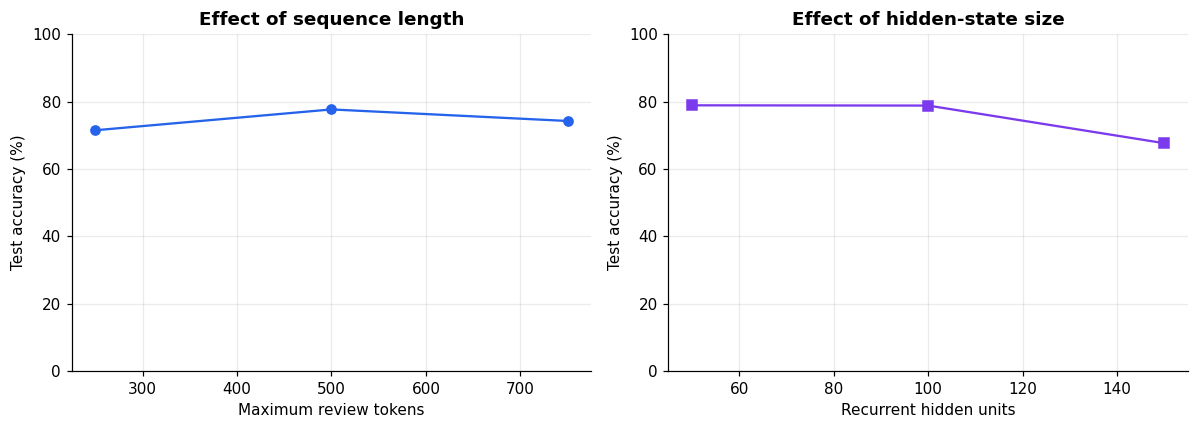

In [18]:
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].plot([r['max_review_length'] for r in length_results],[r['test_accuracy']*100 for r in length_results],marker='o',color=PALETTE[0])
axes[0].set(xlabel='Maximum review tokens',ylabel='Test accuracy (%)',title='Effect of sequence length',ylim=(0,100))
axes[1].plot([r['hidden_units'] for r in hidden_results],[r['test_accuracy']*100 for r in hidden_results],marker='s',color=PALETTE[3])
axes[1].set(xlabel='Recurrent hidden units',ylabel='Test accuracy (%)',title='Effect of hidden-state size',ylim=(0,100))
for ax in axes:ax.grid(alpha=.25)
plt.tight_layout(); plt.show()

## Final Result

The Simple RNN sentiment-classification pipeline has been implemented using the IMDb dataset. The notebook covers tokenization, padding, embedding, recurrent hidden-state processing, model training, evaluation, BPTT, vanishing/exploding gradients, and the two required parameter studies.

## Experimental interpretation

The final test set is reused for the assignment's parameter studies. Those comparisons are exploratory; select a configuration using validation performance before claiming an independent final test result. Accuracy depends on the executed runs, and neither extra hidden units nor a longer sequence guarantees improvement.

In [19]:
import json
from pathlib import Path
summary = {'baseline_test_accuracy': float(baseline_accuracy),
           'length_study': [{'max_review_length': r['max_review_length'], 'test_accuracy': float(r['test_accuracy'])} for r in length_results],
           'hidden_unit_study': [{'hidden_units': r['hidden_units'], 'parameters': r['trainable_params'], 'test_accuracy': float(r['test_accuracy'])} for r in hidden_results]}
Path('imdb_results.json').write_text(json.dumps(summary, indent=2))
display(summary)

{'baseline_test_accuracy': 0.7847200036048889,
 'length_study': [{'max_review_length': 250,
   'test_accuracy': 0.7148799896240234},
  {'max_review_length': 500, 'test_accuracy': 0.7766799926757812},
  {'max_review_length': 750, 'test_accuracy': 0.7424399852752686}],
 'hidden_unit_study': [{'hidden_units': 50,
   'parameters': 324201,
   'test_accuracy': 0.7888799905776978},
  {'hidden_units': 100,
   'parameters': 333401,
   'test_accuracy': 0.7881199717521667},
  {'hidden_units': 150,
   'parameters': 347601,
   'test_accuracy': 0.6764400005340576}]}

## Measured findings

The baseline reached **78.47%** test accuracy. The sequence-length study reached **71.49%**, **77.67%**, and **74.24%** at 250, 500, and 750 tokens. The hidden-unit study reached **78.89%**, **78.81%**, and **67.64%** at 50, 100, and 150 units. The largest network and longest sequences did not yield the best performance.

Repeated 500-token, 100-unit runs differ despite resetting seeds. Random seeds constrain initial conditions but do not guarantee bitwise deterministic GPU execution. These single-run comparisons are exploratory rather than evidence of a statistically reliable ranking.